#import library

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

#import data

In [ ]:
from google.colab import files
uploaded=files.upload()

Saving Churn_Modelling (1).csv to Churn_Modelling (1).csv


In [ ]:
df=pd.read_csv('Churn_Modelling (1).csv')
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


#check dataset

In [ ]:
print(df.info())
print(df.isnull().sum())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB
None
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geogr

#check distribution

Exited
0    7963
1    2037
Name: count, dtype: int64


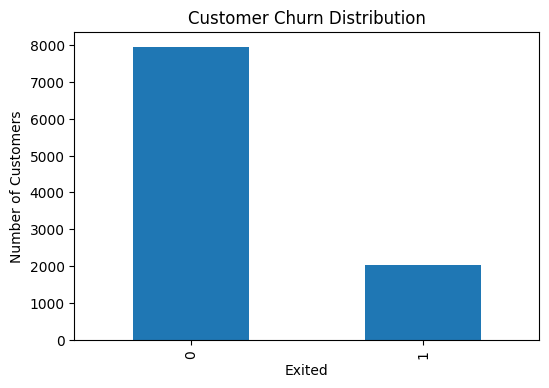

In [ ]:
print(df["Exited"].value_counts())

df["Exited"].value_counts().plot(
    kind="bar",
    figsize=(6,4)
)

plt.title("Customer Churn Distribution")
plt.xlabel("Exited")
plt.ylabel("Number of Customers")
plt.show()

#0 = Customer stayed
1 = Customer churned

#remove unnecesary columns

In [ ]:
df = df.drop(
    ["RowNumber", "CustomerId", "Surname"],
    axis=1
)

#Convert categorical columns

#Geography
#Gender

In [ ]:
df = pd.get_dummies(
    df,
    columns=["Geography", "Gender"],
    drop_first=True
)

df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


#seperate x and y

In [ ]:
X = df.drop("Exited", axis=1)
y = df["Exited"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10000, 11)
y shape: (10000,)


#train_test split

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (8000, 11)
Testing: (2000, 11)


#feature scaling

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#build deep learning with ann

In [ ]:
model = Sequential([

    Dense(
        64,
        activation="relu",
        input_shape=(X_train.shape[1],)
    ),

    Dropout(0.3),

    Dense(
        32,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu"
    ),

    Dense(
        1,
        activation="sigmoid"
    )
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#compile the model

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

#early stopping

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

#train the model

In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.20,
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7852 - loss: 0.4983 - val_accuracy: 0.8138 - val_loss: 0.4378
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8102 - loss: 0.4418 - val_accuracy: 0.8306 - val_loss: 0.4195
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8131 - loss: 0.4302 - val_accuracy: 0.8394 - val_loss: 0.4002
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8216 - loss: 0.4112 - val_accuracy: 0.8519 - val_loss: 0.3787
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8298 - loss: 0.3949 - val_accuracy: 0.8619 - val_loss: 0.3569
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8367 - loss: 0.3795 - val_accuracy: 0.8650 - val_loss: 0.3466
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8391 - loss: 0.3805 - val_accuracy: 0.8681 - val_loss: 0.3437
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8450 - loss: 0.3731 - val_accu

#evaluate the model

In [ ]:
loss, accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

Test Loss: 0.33787626028060913
Test Accuracy: 0.8654999732971191


#training vs validation accuracy

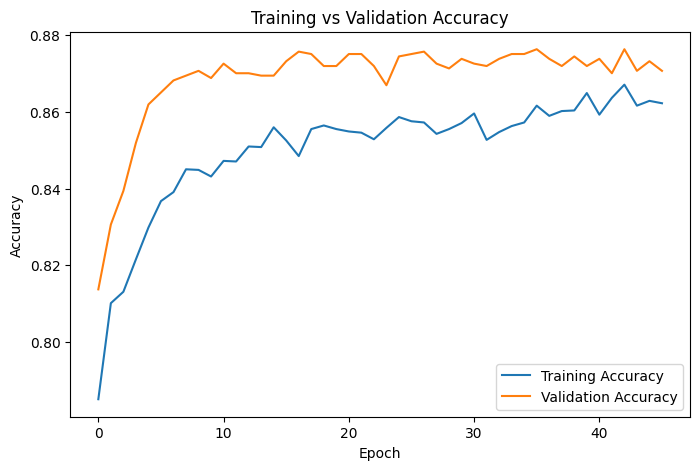

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.show()

#training vs validation loss

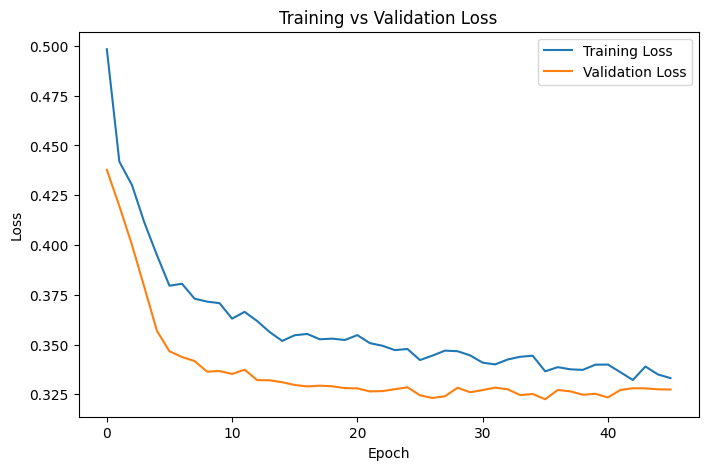

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.show()

#make prediction

In [ ]:
y_probability = model.predict(X_test)

y_pred = (
    y_probability >= 0.5
).astype(int).ravel()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


#classification report

In [ ]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Stayed",
            "Churned"
        ]
    )
)

              precision    recall  f1-score   support

      Stayed       0.88      0.97      0.92      1593
     Churned       0.79      0.46      0.58       407

    accuracy                           0.87      2000
   macro avg       0.83      0.72      0.75      2000
weighted avg       0.86      0.87      0.85      2000



#confusion matrix

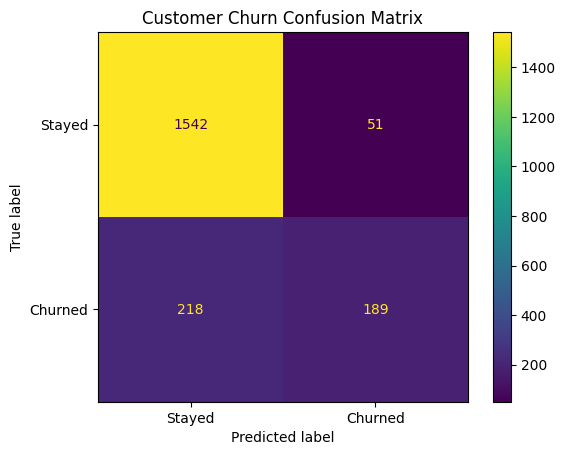

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Stayed",
        "Churned"
    ]
)

disp.plot()

plt.title("Customer Churn Confusion Matrix")
plt.show()

#ROC AUC

In [ ]:
auc = roc_auc_score(
    y_test,
    y_probability
)

print("ROC-AUC Score:", auc)

ROC-AUC Score: 0.8590269776710455


#Plot ROC curve:

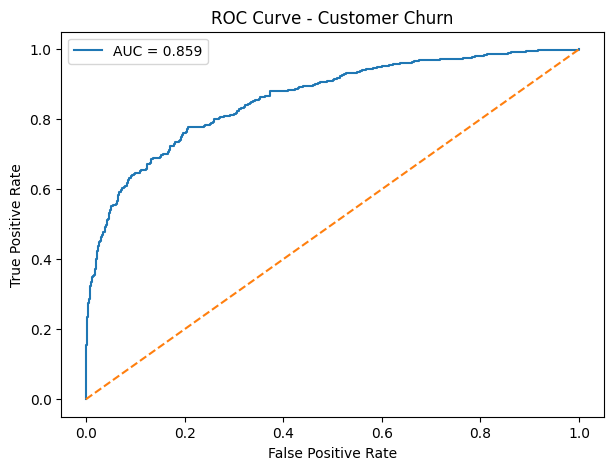

In [ ]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_probability
)

plt.figure(figsize=(7,5))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Customer Churn")
plt.legend()

plt.show()

#PREDICTION NEW CUSTOMER

In [ ]:
new_customer = pd.DataFrame({
    "CreditScore": [650],
    "Age": [40],
    "Tenure": [3],
    "Balance": [60000],
    "NumOfProducts": [1],
    "HasCrCard": [1],
    "IsActiveMember": [0],
    "EstimatedSalary": [80000],
    "Geography_Germany": [1],
    "Geography_Spain": [0],
    "Gender_Male": [1]
})

#Make sure the columns match training data:

In [ ]:
new_customer = new_customer.reindex(
    columns=X.columns,
    fill_value=0
)

In [ ]:
new_customer_scaled = scaler.transform(
    new_customer
)

#PREDICT

In [ ]:
probability = model.predict(
    new_customer_scaled
)[0][0]

print("Churn Probability:", probability)

if probability >= 0.5:
    print("Prediction: CUSTOMER WILL CHURN")
else:
    print("Prediction: CUSTOMER WILL STAY")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Churn Probability: 0.43874466
Prediction: CUSTOMER WILL STAY


#SAVE THE MODEL

In [ ]:
model.save(
    "customer_churn_deep_learning.keras"
)

#SAVE THE SCALER

In [ ]:
import joblib

joblib.dump(
    scaler,
    "customer_churn_scaler.pkl"
)

['customer_churn_scaler.pkl']